# DATA 266 — Homework 8: Mini Diffusion Model

This notebook implements forward diffusion, a small DDPM noise-prediction CNN, DDPM sampling, and DDIM sampling with 50 and 20 steps.

In [1]:
# libraries for this homework
import os
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image

# last 4 of my SJSUid - 0670; use the same seed as the earlier homework
SEED = 670
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
T = 100
BETA_START = 1e-4
BETA_END = 0.02
BATCH_SIZE = 128
EPOCHS = 50
IMG_SIZE = 28
os.makedirs('figures', exist_ok=True)
os.makedirs('checkpoints', exist_ok=True)
os.makedirs('outputs', exist_ok=True)
print('device:', device)

device: mps


## 1. Diffusion schedule and forward process

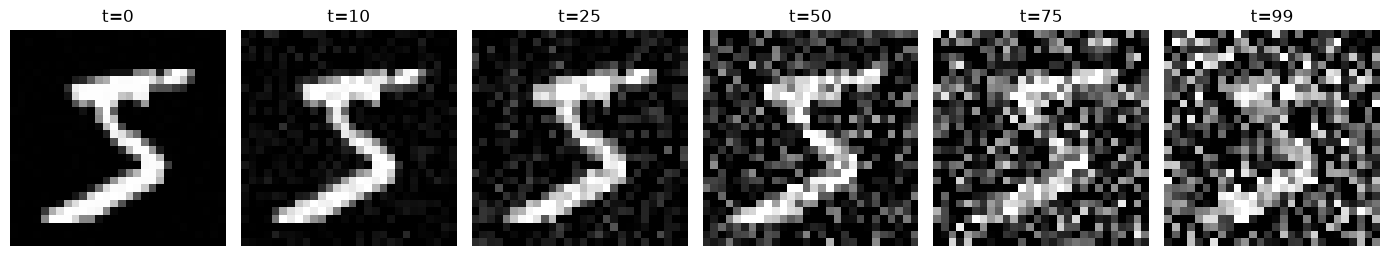

In [2]:
# forward diffusion schedule: beta, alpha, and cumulative alpha-bar
betas = torch.linspace(BETA_START, BETA_END, T, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
alpha_bars_prev = F.pad(alpha_bars[:-1], (1, 0), value=1.0)
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)
posterior_variance = betas * (1.0 - alpha_bars_prev) / (1.0 - alpha_bars)

# pull the timestep-specific scalar out and reshape it for image broadcasting
def extract(values, t, x_shape):
    out = values.gather(0, t)
    return out.reshape(t.shape[0], *((1,) * (len(x_shape) - 1)))

def q_sample(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)
    return (extract(sqrt_alpha_bars, t, x0.shape) * x0
            + extract(sqrt_one_minus_alpha_bars, t, x0.shape) * noise), noise

# load MNIST and scale pixels from [0, 1] to [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x * 2.0 - 1.0),
])
train_data = datasets.MNIST('./data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('./data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True)

# visualize one image after several forward-noise steps
x0, label = train_data[0]
x0 = x0.unsqueeze(0).to(device)
show_steps = [0, 10, 25, 50, 75, 99]
fig, axes = plt.subplots(1, len(show_steps), figsize=(14, 2.5))
for ax, step in zip(axes, show_steps):
    t = torch.tensor([step], device=device)
    xt, _ = q_sample(x0, t)
    ax.imshow(((xt[0, 0].detach().cpu() + 1) / 2).clamp(0, 1), cmap='gray')
    ax.set_title(f't={step}')
    ax.axis('off')
plt.tight_layout()
plt.savefig('figures/forward_diffusion.png', dpi=150)
plt.show()

## 2. Timestep-conditioned CNN noise predictor

In [3]:
# timestep-conditioned CNN: five convolutional layers, ReLU, same input/output shape
class NoisePredictor(nn.Module):
    def __init__(self, timesteps, time_dim=64):
        super().__init__()
        self.time_embed = nn.Sequential(
            nn.Embedding(timesteps, time_dim),
            nn.Linear(time_dim, time_dim),
            nn.ReLU(),
        )
        self.time_layers = nn.ModuleList([
            nn.Linear(time_dim, 32),
            nn.Linear(time_dim, 64),
            nn.Linear(time_dim, 64),
            nn.Linear(time_dim, 32),
        ])
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 64, 3, padding=1)
        self.conv4 = nn.Conv2d(64, 32, 3, padding=1)
        self.conv5 = nn.Conv2d(32, 1, 3, padding=1)

    def forward(self, x, t):
        te = self.time_embed(t)
        h = F.relu(self.conv1(x) + self.time_layers[0](te)[:, :, None, None])
        h = F.relu(self.conv2(h) + self.time_layers[1](te)[:, :, None, None])
        h = F.relu(self.conv3(h) + self.time_layers[2](te)[:, :, None, None])
        h = F.relu(self.conv4(h) + self.time_layers[3](te)[:, :, None, None])
        return self.conv5(h)

model = NoisePredictor(T).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print('parameters:', sum(p.numel() for p in model.parameters()))
print('output shape:', model(torch.randn(2, 1, 28, 28, device=device), torch.tensor([0, 1], device=device)).shape)

parameters: 97537
output shape: torch.Size([2, 1, 28, 28])


## 3. Training

epoch 01/50 loss=0.164547
epoch 02/50 loss=0.086905
epoch 03/50 loss=0.079504
epoch 04/50 loss=0.076892
epoch 05/50 loss=0.073846
epoch 06/50 loss=0.072255
epoch 07/50 loss=0.070972
epoch 08/50 loss=0.069976
epoch 09/50 loss=0.068924
epoch 10/50 loss=0.068250
epoch 11/50 loss=0.067725
epoch 12/50 loss=0.067098
epoch 13/50 loss=0.066945
epoch 14/50 loss=0.066338
epoch 15/50 loss=0.065568
epoch 16/50 loss=0.065222
epoch 17/50 loss=0.064999
epoch 18/50 loss=0.065053
epoch 19/50 loss=0.064922
epoch 20/50 loss=0.063924
epoch 21/50 loss=0.064059
epoch 22/50 loss=0.063856
epoch 23/50 loss=0.063761
epoch 24/50 loss=0.063413
epoch 25/50 loss=0.062969
epoch 26/50 loss=0.063540
epoch 27/50 loss=0.063198
epoch 28/50 loss=0.063019
epoch 29/50 loss=0.062496
epoch 30/50 loss=0.062630
epoch 31/50 loss=0.062645
epoch 32/50 loss=0.062619
epoch 33/50 loss=0.062862
epoch 34/50 loss=0.061873
epoch 35/50 loss=0.061892
epoch 36/50 loss=0.062338
epoch 37/50 loss=0.062100
epoch 38/50 loss=0.061904
epoch 39/50 

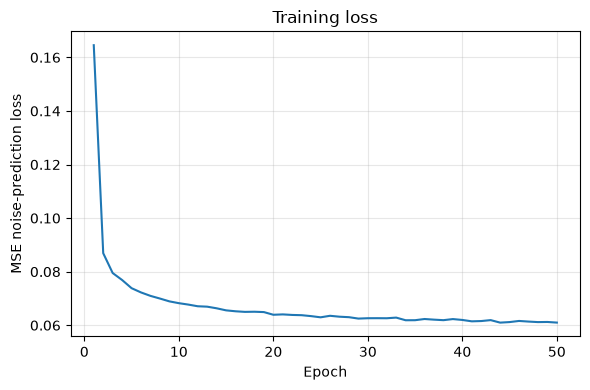

In [4]:
# train the network to predict the exact Gaussian noise used in q_sample
loss_history = []
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    for x0, _ in train_loader:
        x0 = x0.to(device)
        t = torch.randint(0, T, (x0.shape[0],), device=device)
        xt, noise = q_sample(x0, t)
        predicted_noise = model(xt, t)
        loss = F.mse_loss(predicted_noise, noise)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * x0.shape[0]
    epoch_loss = running_loss / len(train_loader.dataset)
    loss_history.append(epoch_loss)
    print(f'epoch {epoch + 1:02d}/{EPOCHS} loss={epoch_loss:.6f}')

# save the trained model and plot the training loss
torch.save({'model': model.state_dict(), 'loss_history': loss_history}, 'checkpoints/mini_diffusion.pt')
plt.figure(figsize=(6, 4))
plt.plot(range(1, EPOCHS + 1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('MSE noise-prediction loss')
plt.title('Training loss')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/train_loss.png', dpi=150)
plt.show()

## 4. DDPM sampling

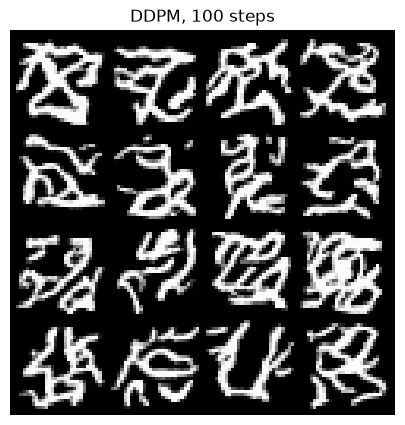

In [5]:
# DDPM reverse sampler: use all 100 steps and add posterior noise except at t=0
@torch.no_grad()
def ddpm_sample(model, n, shape=(1, 28, 28)):
    model.eval()
    x = torch.randn(n, *shape, device=device)
    for step in reversed(range(T)):
        t = torch.full((n,), step, device=device, dtype=torch.long)
        eps = model(x, t)
        beta_t = betas[step]
        alpha_t = alphas[step]
        alpha_bar_t = alpha_bars[step]
        mean = (x - beta_t / torch.sqrt(1.0 - alpha_bar_t) * eps) / torch.sqrt(alpha_t)
        if step > 0:
            x = mean + torch.sqrt(posterior_variance[step]) * torch.randn_like(x)
        else:
            x = mean
    return x.clamp(-1, 1)

ddpm_images = ddpm_sample(model, 16)
save_image((ddpm_images + 1) / 2, 'outputs/ddpm_100_steps.png', nrow=4)
plt.figure(figsize=(5, 5))
plt.imshow(make_grid((ddpm_images + 1) / 2, nrow=4).permute(1, 2, 0).cpu(), cmap='gray')
plt.title('DDPM, 100 steps')
plt.axis('off')
plt.show()

## 5. DDIM sampling

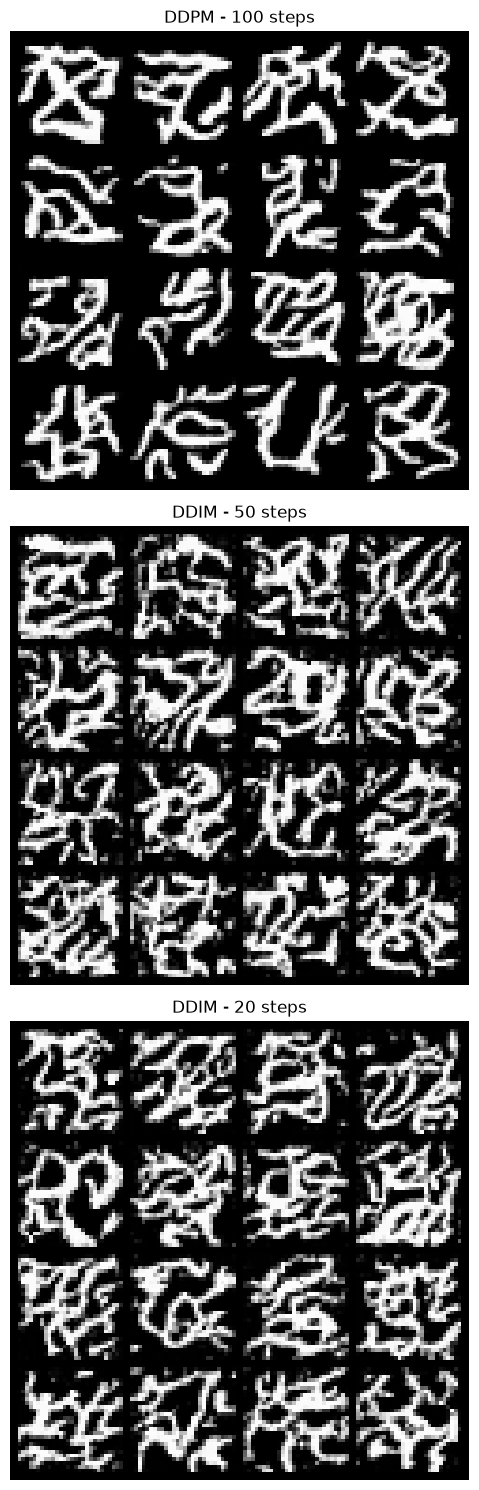

In [6]:
# DDIM sampler: use a shorter timestep schedule; eta=0 makes this deterministic
@torch.no_grad()
def ddim_sample(model, n, steps, eta=0.0, shape=(1, 28, 28)):
    model.eval()
    x = torch.randn(n, *shape, device=device)
    schedule = torch.linspace(T - 1, 0, steps, device=device).round().long()
    schedule = torch.unique_consecutive(schedule)
    for i, step in enumerate(schedule):
        t = torch.full((n,), int(step.item()), device=device, dtype=torch.long)
        eps = model(x, t)
        alpha_bar_t = alpha_bars[step]
        x0_pred = (x - torch.sqrt(1.0 - alpha_bar_t) * eps) / torch.sqrt(alpha_bar_t)
        x0_pred = x0_pred.clamp(-1, 1)
        if i == len(schedule) - 1:
            alpha_bar_prev = torch.tensor(1.0, device=device)
        else:
            alpha_bar_prev = alpha_bars[schedule[i + 1]]
        sigma = eta * torch.sqrt(((1.0 - alpha_bar_prev) / (1.0 - alpha_bar_t)) * (1.0 - alpha_bar_t / alpha_bar_prev))
        direction = torch.sqrt(torch.clamp(1.0 - alpha_bar_prev - sigma ** 2, min=0.0)) * eps
        noise = torch.randn_like(x) if eta > 0 and i < len(schedule) - 1 else torch.zeros_like(x)
        x = torch.sqrt(alpha_bar_prev) * x0_pred + direction + sigma * noise
    return x.clamp(-1, 1)

ddim50_images = ddim_sample(model, 16, steps=50, eta=0.0)
ddim20_images = ddim_sample(model, 16, steps=20, eta=0.0)
save_image((ddim50_images + 1) / 2, 'outputs/ddim_50_steps.png', nrow=4)
save_image((ddim20_images + 1) / 2, 'outputs/ddim_20_steps.png', nrow=4)

fig, axes = plt.subplots(3, 1, figsize=(5, 15))
for ax, images, title in zip(axes, [ddpm_images, ddim50_images, ddim20_images], ['DDPM - 100 steps', 'DDIM - 50 steps', 'DDIM - 20 steps']):
    ax.imshow(make_grid((images + 1) / 2, nrow=4).permute(1, 2, 0).cpu(), cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.savefig('figures/ddpm_vs_ddim.png', dpi=150)
plt.show()

## 6. Discussion

The training loss went from 0.164547 in epoch 1 to 0.061000 in epoch 50. The loss dropped quickly at the beginning and then flattened around 0.061. The CNN output has the required shape `(2, 1, 28, 28)` and has 97,537 trainable parameters.

On my run, the DDPM samples were still mostly loose digit-like strokes rather than clean MNIST digits. DDIM with 50 steps and 20 steps was also noisy, and the 20-step images were not clearly better. The main comparison here is that DDIM uses fewer reverse evaluations, while the image quality in this small run was limited by the model and training setup. I am not claiming that DDIM improved the samples just because it was faster.